In [29]:
# load dataset
import pandas as pd

df = pd.read_csv("majors.csv")
df

,Unnamed: 0,id_major,id_university,type,major_name,capacity
0,0,1111014,111,science,PENDIDIKAN DOKTER HEWAN,88
1,1,1111022,111,science,TEKNIK SIPIL,64
2,2,1111037,111,science,TEKNIK MESIN,48
3,3,1111045,111,science,TEKNIK KIMIA,48
4,4,1111053,111,science,ARSITEKTUR,48
...,...,...,...,...,...,...
3162,3162,9212011,921,humanities,EKONOMI PEMBANGUNAN,32
3163,3163,9212042,921,humanities,MANAJEMEN,32
3164,3164,9212057,921,humanities,AKUNTANSI,32
3165,3165,9212065,921,humanities,PENDIDIKAN BAHASA INDONESIA,16


In [30]:
# EDA
print(f"cek 5 data teratas \n {df.head()} \n")

print(f"cek tipe data \n {df.dtypes} \n")

print(f"cek missing values \n {df.isnull().sum()} \n")

print(f"cek duplicate data \n {df.duplicated().sum()}")

cek 5 data teratas 
    Unnamed: 0  id_major  id_university     type               major_name  \
0           0   1111014            111  science  PENDIDIKAN DOKTER HEWAN   
1           1   1111022            111  science             TEKNIK SIPIL   
2           2   1111037            111  science             TEKNIK MESIN   
3           3   1111045            111  science             TEKNIK KIMIA   
4           4   1111053            111  science               ARSITEKTUR   

   capacity  
0        88  
1        64  
2        48  
3        48  
4        48   

cek tipe data 
 Unnamed: 0       int64
id_major         int64
id_university    int64
type               str
major_name         str
capacity         int64
dtype: object 

cek missing values 
 Unnamed: 0       0
id_major         0
id_university    0
type             0
major_name       0
capacity         0
dtype: int64 

cek duplicate data 
 0


In [31]:
# cleaning data
df = df.drop(columns='Unnamed: 0')
df = df.drop(columns='id_major')
df = df.drop(columns='id_university')

In [32]:
# cek outlier
numerical_columns = df.select_dtypes(include='number').columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    outlier_summary.append({
        'kolom': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'batas_bawah': lower_bound,
        'batas_atas': upper_bound,
        'jumlah_outlier': len(outliers),
        'persen_outlier': round(len(outliers) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,capacity,32.0,60.0,28.0,-10.0,102.0,188,5.94


In [34]:
# handle outlier
df_capped = df.copy()

for column in numerical_columns:

    Q1 = df_capped[column].quantile(0.25)
    Q3 = df_capped[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)

    df_capped[column] = df_capped[column].clip(
        lower=lower,
        upper=upper
    )

In [35]:
# training model
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(max_depth=2, random_state=100)
rf.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",100
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [37]:
# evaluate model
from sklearn.metrics import mean_squared_error, r2_score

# prediction
y_rf_train_pred = rf.predict(x_train)
y_rf_test_pred = rf.predict(x_test)

# training evaluation
rf_train_mse = mean_squared_error(y_train, y_rf_train_pred)
rf_train_r2 = r2_score(y_train, y_rf_train_pred)

# testing evaluation
rf_test_mse = mean_squared_error(y_test, y_rf_test_pred)
rf_test_r2 = r2_score(y_test, y_rf_test_pred)

# print evaluation
print("Random Forest Training MSE:", rf_train_mse)
print("Random Forest Training R2:", rf_train_r2)

print("Random Forest Testing MSE:", rf_test_mse)
print("Random Forest Testing R2:", rf_test_r2)

Random Forest Training MSE: 1044.3146987702032
Random Forest Training R2: 0.17111802978210777
Random Forest Testing MSE: 869.2837829882292
Random Forest Testing R2: 0.17140922883670395


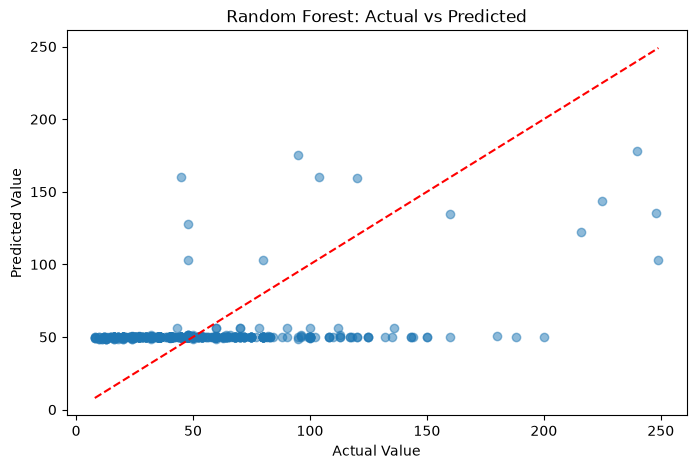

In [38]:
# visualisasi
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_rf_test_pred, alpha=0.5)

# garis prediksi sempurna
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Value")
plt.ylabel("Predicted Value")
plt.title("Random Forest: Actual vs Predicted")

plt.show()


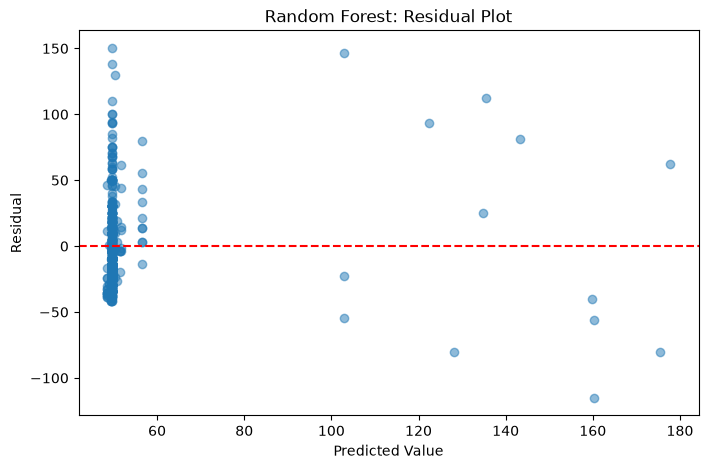

In [39]:
residuals = y_test - y_rf_test_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_rf_test_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Value")
plt.ylabel("Residual")
plt.title("Random Forest: Residual Plot")

plt.show()


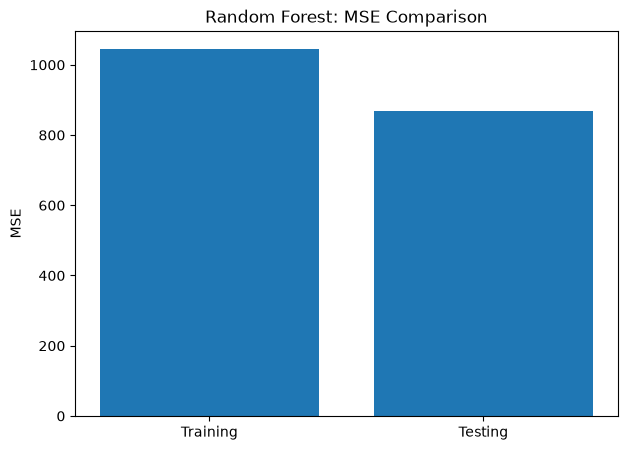

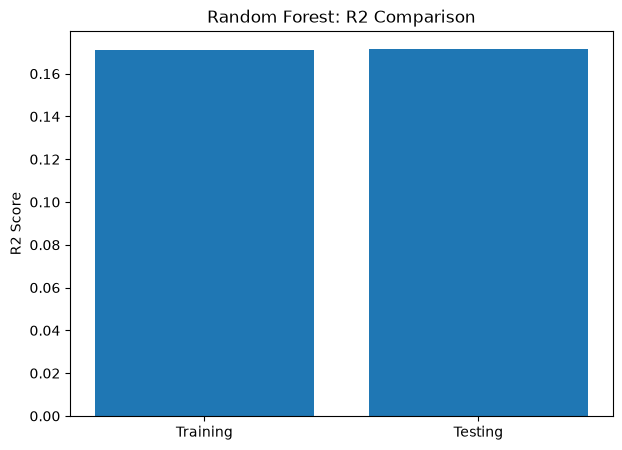

In [40]:
# MSE comparison
plt.figure(figsize=(7, 5))

plt.bar(
    ["Training", "Testing"],
    [rf_train_mse, rf_test_mse]
)

plt.ylabel("MSE")
plt.title("Random Forest: MSE Comparison")

plt.show()


# R2 comparison
plt.figure(figsize=(7, 5))

plt.bar(
    ["Training", "Testing"],
    [rf_train_r2, rf_test_r2]
)

plt.ylabel("R2 Score")
plt.title("Random Forest: R2 Comparison")

plt.show()


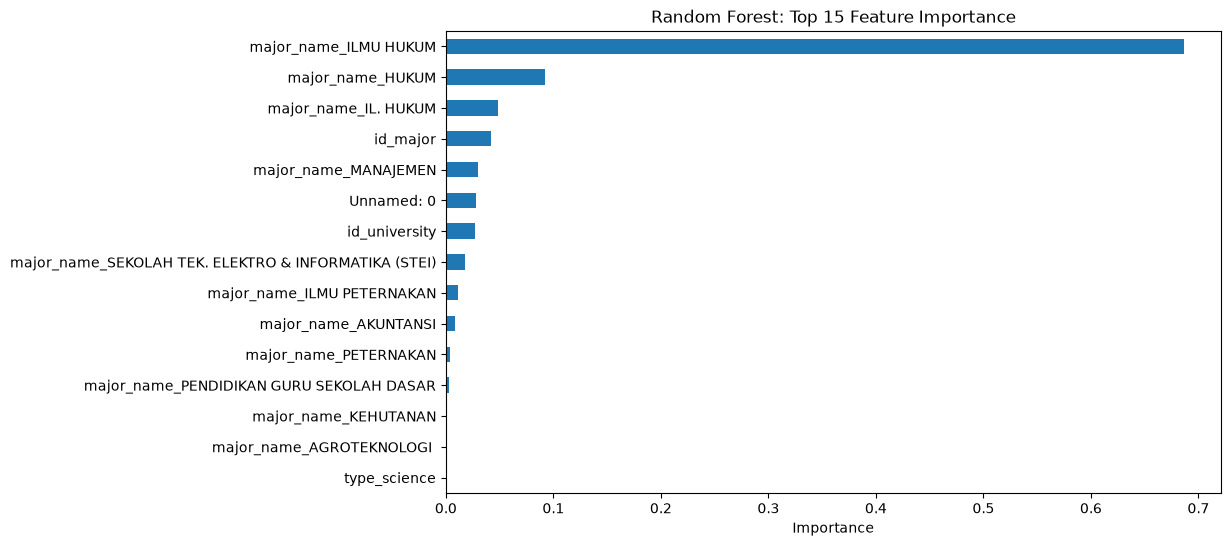

In [42]:
feature_importance = pd.Series(
    rf.feature_importances_,
    index=x_train.columns
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

plt.figure(figsize=(10, 6))

feature_importance.head(15).plot(kind="barh")

plt.xlabel("Importance")
plt.title("Random Forest: Top 15 Feature Importance")

plt.gca().invert_yaxis()

plt.show()


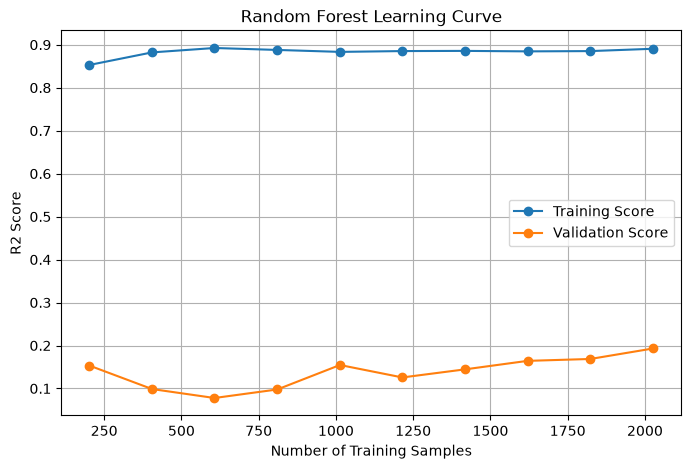

In [43]:
# learning curve
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import learning_curve
from sklearn.ensemble import RandomForestRegressor

# model Random Forest
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# learning curve
train_sizes, train_scores, val_scores = learning_curve(
    estimator=rf,
    X=x_train,
    y=y_train,
    cv=5,
    scoring='r2',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

# rata-rata score
train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# visualisasi
plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Training Score'
)

plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Validation Score'
)

plt.xlabel("Number of Training Samples")
plt.ylabel("R2 Score")
plt.title("Random Forest Learning Curve")

plt.legend()
plt.grid(True)

plt.show()
